# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [2]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,...,codigo_municipio,nombre_departamento_divipola,nombre_municipio_divipola,longitud_territorial,latitud_territorial,estado_union,indicador_merge,estado_union_inicial,fuente_territorial,corte_divipola
0,0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,...,52835,NARIÑO,SAN ANDRÉS DE TUMACO,-78.764073,1.807399,coincide,both,coincide,divipola.csv,2024
1,1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,...,41676,HUILA,SANTA MARÍA,-75.586223,2.939603,coincide,both,coincide,divipola.csv,2024
2,2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,coincide,divipola.csv,2024
3,3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,coincide,divipola.csv,2024
4,4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,coincide,divipola.csv,2024


(92738, 50)
id_fila                                        int64
Secuencial                                    object
Fecha de Análisis                             object
Departamento                                  object
Municipio                                     object
Cultivo                                       object
Estado                                        object
Tiempo de establecimiento                     object
Topografia                                    object
Drenaje                                       object
Riego                                         object
Fertilizantes aplicados                       object
pH agua:suelo                                 object
Materia organica                              object
Fósforo Bray II                               object
Azufre Fosfato monocalcico                    object
Acidez Intercambiable                         object
Aluminio intercambiable                       object
Calcio intercambiable             

In [3]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 50)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ id_fila ┆ Secuencial ┆ Fecha de  ┆ Departame ┆ … ┆ indicador ┆ estado_un ┆ fuente_te ┆ corte_div │
│ ---     ┆ ---        ┆ Análisis  ┆ nto       ┆   ┆ _merge    ┆ ion_inici ┆ rritorial ┆ ipola     │
│ i64     ┆ str        ┆ ---       ┆ ---       ┆   ┆ ---       ┆ al        ┆ ---       ┆ ---       │
│         ┆            ┆ str       ┆ str       ┆   ┆ str       ┆ ---       ┆ str       ┆ str       │
│         ┆            ┆           ┆           ┆   ┆           ┆ str       ┆           ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 0       ┆ 1          ┆ 7/01/2014 ┆ NARIÑO    ┆ … ┆ both      ┆ coincide  ┆ divipola. ┆ 2024      │
│         ┆            ┆           ┆           ┆   ┆           ┆           ┆ csv       ┆           │
│ 1       ┆ 2          ┆ 21/08/201 ┆ HUILA     ┆ … ┆ both      ┆ coincide  ┆

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [4]:
# Desarrollo
# Prepara la proyección común e implementa la consulta en ambos motores.

COLS = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]
TIPOS_CSV_PD = {"id_fila": "int64", "anio": "Int64", "codigo_departamento": "str", "codigo_municipio": "str", "ph": "float64", "ph_valido": "bool"}
TIPOS_CSV_PL = {"id_fila": pl.Int64, "anio": pl.Int64, "codigo_departamento": pl.String, "codigo_municipio": pl.String, "ph": pl.Float64, "ph_valido": pl.String}
proyeccion_pd = datos_pd[COLS].astype({"id_fila": "int64", "anio": "Int64", "ph": "float64", "ph_valido": "bool"})
proyeccion_pl = datos_pl.select(COLS).cast({"id_fila": pl.Int64, "anio": pl.Int64, "ph": pl.Float64, "ph_valido": pl.Boolean})

print(proyeccion_pd.shape, proyeccion_pl.shape)
print('----------------------------')
print(proyeccion_pd["codigo_municipio"].str.len().value_counts(dropna=False).to_dict())
print('----------------------------')
print(proyeccion_pl["codigo_municipio"].str.len_chars().value_counts())

(92738, 6) (92738, 6)
----------------------------
{5.0: 90600, nan: 2138}
----------------------------
shape: (2, 2)
┌──────────────────┬───────┐
│ codigo_municipio ┆ count │
│ ---              ┆ ---   │
│ u32              ┆ u32   │
╞══════════════════╪═══════╡
│ 5                ┆ 90600 │
│ null             ┆ 2138  │
└──────────────────┴───────┘


In [5]:
anio_sel = int(proyeccion_pd["anio"].value_counts().idxmax())
dep_sel = proyeccion_pd.loc[(proyeccion_pd["anio"] == anio_sel).fillna(False), "codigo_departamento"].value_counts().idxmax()
print("Año:", anio_sel, "| departamento:", dep_sel)

FILTRO_PL = (pl.col("anio") == anio_sel) & (pl.col("codigo_departamento") == dep_sel)
AGG_PL = [
    pl.len().alias("total"),
    pl.col("ph_valido").sum().alias("ph_validos"),
    pl.col("ph").filter(pl.col("ph_valido")).mean().alias("ph_media"),
]

sel_pd = proyeccion_pd[(proyeccion_pd["anio"] == anio_sel) & (proyeccion_pd["codigo_departamento"] == dep_sel)]
consulta_pd = (
    sel_pd.assign(ph_aux=sel_pd["ph"].where(sel_pd["ph_valido"]))
    .groupby("codigo_municipio", dropna=False)
    .agg(total=("id_fila", "size"), ph_validos=("ph_valido", "sum"), ph_media=("ph_aux", "mean"))
    .reset_index()
)
consulta_pl = proyeccion_pl.filter(FILTRO_PL).group_by("codigo_municipio").agg(AGG_PL)

a = consulta_pd.sort_values("codigo_municipio", na_position="last").reset_index(drop=True)
b = consulta_pl.sort("codigo_municipio", nulls_last=True).to_pandas()
print("Claves iguales:", a["codigo_municipio"].fillna("<nulo>").tolist() == b["codigo_municipio"].fillna("<nulo>").tolist())

pd.testing.assert_frame_equal(a, b, check_dtype=False, check_exact=False, atol=1e-6, rtol=0)
print("Medias ausentes (pandas, Polars):", int(a["ph_media"].isna().sum()), int(b["ph_media"].isna().sum()))

# Control de claves nulas sobre la tabla completa
grupos_pd = proyeccion_pd.groupby("codigo_municipio", dropna=False).size()
grupos_pl = proyeccion_pl.group_by("codigo_municipio").len()
print("Filas con municipio ausente (pandas, Polars):", int(grupos_pd[grupos_pd.index.isna()].sum()), int(grupos_pl.filter(pl.col("codigo_municipio").is_null())["len"].sum()))
display(a)

Año: 2016 | departamento: 25
Claves iguales: True
Medias ausentes (pandas, Polars): 0 0
Filas con municipio ausente (pandas, Polars): 2138 2138


,codigo_municipio,total,ph_validos,ph_media
0,25001,1,1,8.840000
1,25019,3,3,5.360000
2,25035,16,16,6.978125
3,25040,14,14,5.535571
4,25053,5,5,6.553800
...,...,...,...,...
98,25875,136,136,6.620000
99,25878,19,19,5.211526
100,25885,43,43,4.731674
101,25898,4,4,5.685000


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

Ambos motores proyectan las mismas seis columnas y todas las filas, con tipos equivalentes: int64, Int64 nullable para anio, texto para los códigos, float64 para ph y booleano para ph_valido. En CSV los nulos son el campo vacío (na_values=[""] en pandas, null_values=[""] en Polars) y los códigos se leen como texto (str / pl.String), por lo que conservan los ceros iniciales.

El grupo de municipio ausente se verifica sobre la tabla completa: dentro de un departamento no existe, porque municipio y departamento faltan juntos.


## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [6]:
# Desarrollo
# Escribe las cuatro representaciones y presenta su inventario de particiones.

SESION = time.strftime("%Y%m%d_%H%M%S")
EJECUCION_1 = OUT + "/ejecucion_" + SESION + "_1"
EJECUCION_2 = OUT + "/ejecucion_" + SESION + "_2"
EJECUCION = EJECUCION_1
DISENOS = {"por_anio": ["anio"], "por_anio_depto": ["anio", "codigo_departamento"]}
os.makedirs(EJECUCION, exist_ok=False)

proyeccion_pd.to_csv(EJECUCION + "/proyeccion.csv", sep=",", na_rep="", index=False)
proyeccion_pd.to_parquet(EJECUCION + "/proyeccion.parquet", engine="pyarrow", compression="snappy", index=False)

inventarios = {}
for diseno in DISENOS:
    claves = DISENOS[diseno]
    carpeta = Path(EJECUCION) / diseno
    carpeta.mkdir(parents=True, exist_ok=False)
    filas = []
    for numero, (valores, grupo) in enumerate(proyeccion_pd.groupby(claves, dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        fila = dict(zip(claves, valores))
        fila["archivo"] = str(archivo.relative_to(EJECUCION))
        fila["filas"] = len(grupo)
        fila["bytes"] = archivo.stat().st_size
        filas.append(fila)
    inventarios[diseno] = pd.DataFrame(filas).astype({"anio": "Int64"})
    inventarios[diseno].to_csv(EJECUCION + f"/inventario_{diseno}.csv", index=False)
    display(inventarios[diseno].head())

,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96671
1,2015,por_anio/parte-0001.parquet,13228,117800
2,2016,por_anio/parte-0002.parquet,14539,130798
3,2017,por_anio/parte-0003.parquet,7655,72302
4,2018,por_anio/parte-0004.parquet,4208,42190


,anio,codigo_departamento,archivo,filas,bytes
0,2014,05,por_anio_depto/parte-0000.parquet,517,8336
1,2014,08,por_anio_depto/parte-0001.parquet,16,4020
2,2014,11,por_anio_depto/parte-0002.parquet,24,4041
3,2014,13,por_anio_depto/parte-0003.parquet,192,5471
4,2014,15,por_anio_depto/parte-0004.parquet,484,8128


In [7]:
TIPOS_INV = {"anio": "Int64", "codigo_departamento": "str", "archivo": "str", "filas": "int64", "bytes": "int64"}
CODIGOS = ["codigo_departamento", "codigo_municipio"]
ref = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)

csv_leido = pd.read_csv(EJECUCION + "/proyeccion.csv", sep=",", dtype=TIPOS_CSV_PD, keep_default_na=False, na_values=[""], true_values=["True"], false_values=["False"])
pq_leido = pd.read_parquet(EJECUCION + "/proyeccion.parquet", engine="pyarrow")
csv_leido = csv_leido.sort_values("id_fila").reset_index(drop=True)
pq_leido = pq_leido.sort_values("id_fila").reset_index(drop=True)

for tabla in [ref, csv_leido, pq_leido]:
    for c in CODIGOS:
        tabla[c] = tabla[c].astype(object).where(tabla[c].notna(), float("nan"))

pd.testing.assert_frame_equal(csv_leido, ref, check_dtype=False)
pd.testing.assert_frame_equal(pq_leido, ref, check_dtype=False)
print("Bytes CSV / Parquet único:", os.path.getsize(EJECUCION + "/proyeccion.csv"), os.path.getsize(EJECUCION + "/proyeccion.parquet"))

for diseno in DISENOS:
    inv = pd.read_csv(EJECUCION + f"/inventario_{diseno}.csv", dtype=TIPOS_INV, keep_default_na=False, na_values=[""])
    partes = [pd.read_parquet(EJECUCION + "/" + ruta, engine="pyarrow") for ruta in inv["archivo"]]
    leido = pd.concat(partes, ignore_index=True).sort_values("id_fila").reset_index(drop=True)
    for c in CODIGOS:
        leido[c] = leido[c].astype(object).where(leido[c].notna(), float("nan"))
    pd.testing.assert_frame_equal(leido, ref, check_dtype=False)
    assert leido["id_fila"].is_unique and len(leido) == len(ref) and int(inv["filas"].sum()) == len(ref)
    print(diseno, "| archivos:", len(inv), "| bytes:", int(inv["bytes"].sum()), "| más pequeño:", int(inv["bytes"].min()), "| filas mínimas:", int(inv["filas"].min()))

Bytes CSV / Parquet único: 2749328 830508
por_anio | archivos: 12 | bytes: 864848 | más pequeño: 30142 | filas mínimas: 2685
por_anio_depto | archivos: 373 | bytes: 2250245 | más pequeño: 3780 | filas mínimas: 1


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

El control relee todas las partes por ruta, concatena, ordena por id_fila y compara con la proyección; también comprueba que los ID sean únicos y que las filas del inventario sumen el total. 

El diseño por año y departamento genera más archivos y más pequeños que el diseño por año (ver mínimos de bytes y filas).

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [8]:
# Desarrollo
# Mide con llamadas directas a read_csv/read_parquet y to_csv/to_parquet o write_csv/write_parquet.

COLS_MED = ["motor", "version", "operacion", "formato", "particionamiento", "repeticion", "segundos", "filas_entrada", "filas_salida"]
VERSION = {"pandas": pd.__version__, "polars": pl.__version__}
RUTA_CSV = EJECUCION_1 + "/proyeccion.csv"
RUTA_PQ = EJECUCION_1 + "/proyeccion.parquet"
ESCRITURAS = OUT + "/escrituras_" + SESION
os.makedirs(ESCRITURAS, exist_ok=False)
N = len(proyeccion_pd)
registros = []

for repeticion in range(6):  # 0 = ejecución inicial (se guarda aparte); 1-5 = repeticiones medidas
    for motor in (["pandas", "polars"] if repeticion % 2 == 0 else ["polars", "pandas"]):
        if motor == "pandas":
            t0 = time.perf_counter()
            lec_csv_pd = pd.read_csv(RUTA_CSV, sep=",", dtype=TIPOS_CSV_PD, keep_default_na=False, na_values=[""], true_values=["True"], false_values=["False"])
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "leer", "csv", "unico", repeticion, t1 - t0, N, len(lec_csv_pd)))

            t0 = time.perf_counter()
            lec_pq_pd = pd.read_parquet(RUTA_PQ, engine="pyarrow", columns=COLS)
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "leer", "parquet", "unico", repeticion, t1 - t0, N, len(lec_pq_pd)))

            t0 = time.perf_counter()
            proyeccion_pd.to_csv(ESCRITURAS + f"/pandas_{repeticion}.csv", sep=",", na_rep="", index=False)
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "escribir", "csv", "unico", repeticion, t1 - t0, N, N))

            t0 = time.perf_counter()
            proyeccion_pd.to_parquet(ESCRITURAS + f"/pandas_{repeticion}.parquet", engine="pyarrow", compression="snappy", index=False)
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "escribir", "parquet", "unico", repeticion, t1 - t0, N, N))
        else:
            t0 = time.perf_counter()
            lec_csv_pl = pl.read_csv(RUTA_CSV, separator=",", schema_overrides=TIPOS_CSV_PL, null_values=[""]).with_columns(pl.col("ph_valido") == "True")
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "leer", "csv", "unico", repeticion, t1 - t0, N, len(lec_csv_pl)))

            t0 = time.perf_counter()
            lec_pq_pl = pl.read_parquet(RUTA_PQ, columns=COLS)
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "leer", "parquet", "unico", repeticion, t1 - t0, N, len(lec_pq_pl)))

            t0 = time.perf_counter()
            proyeccion_pl.write_csv(ESCRITURAS + f"/polars_{repeticion}.csv", separator=",", null_value="")
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "escribir", "csv", "unico", repeticion, t1 - t0, N, N))

            t0 = time.perf_counter()
            proyeccion_pl.write_parquet(ESCRITURAS + f"/polars_{repeticion}.parquet", compression="snappy")
            t1 = time.perf_counter()
            registros.append((motor, VERSION[motor], "escribir", "parquet", "unico", repeticion, t1 - t0, N, N))

In [9]:
# Controles fuera de la medición
CODIGOS = ["codigo_departamento", "codigo_municipio"]
ref = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
for c in CODIGOS:
    ref[c] = ref[c].astype(object).where(ref[c].notna(), float("nan"))

for obj in [lec_csv_pd, lec_pq_pd, lec_csv_pl.to_pandas(), lec_pq_pl.to_pandas()]:
    tabla = obj.sort_values("id_fila").reset_index(drop=True)
    for c in CODIGOS:
        tabla[c] = tabla[c].astype(object).where(tabla[c].notna(), float("nan"))
    pd.testing.assert_frame_equal(tabla, ref, check_dtype=False)

for motor in ["pandas", "polars"]:
    csv_ok = pd.read_csv(ESCRITURAS + f"/{motor}_5.csv", sep=",", dtype=TIPOS_CSV_PD, keep_default_na=False, na_values=[""], true_values=["True", "true"], false_values=["False", "false"])
    pq_ok = pd.read_parquet(ESCRITURAS + f"/{motor}_5.parquet", engine="pyarrow")
    csv_ok = csv_ok.sort_values("id_fila").reset_index(drop=True)
    pq_ok = pq_ok.sort_values("id_fila").reset_index(drop=True)
    for c in CODIGOS:
        csv_ok[c] = csv_ok[c].astype(object).where(csv_ok[c].notna(), float("nan"))
        pq_ok[c] = pq_ok[c].astype(object).where(pq_ok[c].notna(), float("nan"))
    pd.testing.assert_frame_equal(csv_ok, ref, check_dtype=False)
    pd.testing.assert_frame_equal(pq_ok, ref, check_dtype=False)
    print(motor, "| bytes CSV / Parquet:", os.path.getsize(ESCRITURAS + f"/{motor}_5.csv"), os.path.getsize(ESCRITURAS + f"/{motor}_5.parquet"))

print('-----------------------------------------------------')
medidas = pd.DataFrame(registros, columns=COLS_MED)
print(medidas[medidas["repeticion"] > 0].groupby(["operacion", "formato", "motor"])["segundos"].median())
print('-----------------------------------------------------')
print("Ejecución inicial:")
print(medidas[medidas["repeticion"] == 0][["motor", "operacion", "formato", "segundos"]])
print('-----------------------------------------------------')
print(platform.platform(), "| CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
print('-----------------------------------------------------')
print("RAM disponible (GB):", round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_AVPHYS_PAGES") / 1e9, 2))
print('-----------------------------------------------------')
print("Archivos leídos:", EJECUCION_1, "| escrituras:", ESCRITURAS)

pandas | bytes CSV / Parquet: 2749328 830508
polars | bytes CSV / Parquet: 2749328 761659
-----------------------------------------------------
operacion  formato  motor 
escribir   csv      pandas    0.950386
                    polars    0.181494
           parquet  pandas    0.173699
                    polars    0.066038
leer       csv      pandas    0.154641
                    polars    0.082746
           parquet  pandas    0.047340
                    polars    0.069381
Name: segundos, dtype: float64
-----------------------------------------------------
Ejecución inicial:
    motor operacion  formato  segundos
0  pandas      leer      csv  0.142194
1  pandas      leer  parquet  0.065122
2  pandas  escribir      csv  1.168611
3  pandas  escribir  parquet  0.254177
4  polars      leer      csv  0.217359
5  polars      leer  parquet  0.072928
6  polars  escribir      csv  0.246471
7  polars  escribir  parquet  0.120118
-----------------------------------------------------
Linux-6.

**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

La lectura mide los mismos archivos con el contrato común incluido (tipos explícitos, nulos como vacío y conversión del booleano en Polars). La escritura parte de los datos ya residentes en memoria y cada repetición usa una ruta nueva. Hay una ejecución inicial aparte y cinco repeticiones con orden de motores alternado.

Opciones que no se pueden igualar del todo: pandas escribe el booleano como True/False y Polars como true/false, y los metadatos de Parquet difieren, así que los bytes no son idénticos.

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [10]:
# Desarrollo
# Ejecuta los dos experimentos y comprueba resultados materializados equivalentes.

inv_a = inventarios["por_anio"]
inv_d = inventarios["por_anio_depto"]
n_a = int((inv_a["anio"] == anio_sel).sum())
n_d = int(((inv_d["anio"] == anio_sel) & (inv_d["codigo_departamento"] == dep_sel)).sum())
print("Archivos candidatos (por año, por año/departamento):", n_a, n_d)
assert n_a > 0 and n_d > 0, "Sin archivos candidatos: elige otro año o departamento"
resultados = {}
rutas_usadas = {}

# Experimento 1: en memoria (solo filtro y agregación)
for repeticion in range(6):
    for motor in (["pandas", "polars"] if repeticion % 2 == 0 else ["polars", "pandas"]):
        if motor == "pandas":
            t0 = time.perf_counter()
            sel = proyeccion_pd[(proyeccion_pd["anio"] == anio_sel) & (proyeccion_pd["codigo_departamento"] == dep_sel)]
            res = (
                sel.assign(ph_aux=sel["ph"].where(sel["ph_valido"]))
                .groupby("codigo_municipio", dropna=False)
                .agg(total=("id_fila", "size"), ph_validos=("ph_valido", "sum"), ph_media=("ph_aux", "mean"))
                .reset_index()
            )
            t1 = time.perf_counter()
        else:
            t0 = time.perf_counter()
            res = proyeccion_pl.filter(FILTRO_PL).group_by("codigo_municipio").agg(AGG_PL)
            t1 = time.perf_counter()
        resultados[(motor, "memoria")] = res
        registros.append((motor, VERSION[motor], "filtrar_agregar", "memoria", "tabla_en_memoria", repeticion, t1 - t0, N, len(res)))

Archivos candidatos (por año, por año/departamento): 1 1


In [11]:
# Experimento 2: desde disco (inventario, selección de rutas, lectura, concat, filtro y agregación)
for repeticion in range(6):
    for motor in (["pandas", "polars"] if repeticion % 2 == 0 else ["polars", "pandas"]):
        for diseno in ["unico", "por_anio", "por_anio_depto"]:
            t0 = time.perf_counter()
            if diseno == "unico":
                rutas = [EJECUCION_1 + "/proyeccion.parquet"]
            else:
                inv = pd.read_csv(EJECUCION_1 + f"/inventario_{diseno}.csv", dtype=TIPOS_INV, keep_default_na=False, na_values=[""])
                mascara = inv["anio"] == anio_sel
                if diseno == "por_anio_depto":
                    mascara = mascara & (inv["codigo_departamento"] == dep_sel)
                rutas = [EJECUCION_1 + "/" + ruta for ruta in inv.loc[mascara.fillna(False), "archivo"]]
            if motor == "pandas":
                partes_pd = []
                for ruta in rutas:
                    partes_pd.append(pd.read_parquet(ruta, engine="pyarrow", columns=COLS))
                leidas = pd.concat(partes_pd, ignore_index=True)
                sel = leidas[(leidas["anio"] == anio_sel) & (leidas["codigo_departamento"] == dep_sel)]
                res = (
                    sel.assign(ph_aux=sel["ph"].where(sel["ph_valido"]))
                    .groupby("codigo_municipio", dropna=False)
                    .agg(total=("id_fila", "size"), ph_validos=("ph_valido", "sum"), ph_media=("ph_aux", "mean"))
                    .reset_index()
                )
            else:
                partes_pl = []
                for ruta in rutas:
                    partes_pl.append(pl.read_parquet(ruta, columns=COLS))
                leidas = pl.concat(partes_pl)
                res = leidas.filter(FILTRO_PL).group_by("codigo_municipio").agg(AGG_PL)
            t1 = time.perf_counter()
            resultados[(motor, diseno)] = res
            rutas_usadas[(motor, diseno)] = rutas
            registros.append((motor, VERSION[motor], "consulta_disco", "parquet", diseno, repeticion, t1 - t0, len(leidas), len(res)))

In [12]:
# Consulta diferida (scan_parquet + collect) frente a lectura inmediata, sobre el Parquet único
for repeticion in range(6):
    for modo in (["diferida", "inmediata"] if repeticion % 2 == 0 else ["inmediata", "diferida"]):
        t0 = time.perf_counter()
        if modo == "diferida":
            res = pl.scan_parquet(RUTA_PQ).select(COLS).filter(FILTRO_PL).group_by("codigo_municipio").agg(AGG_PL).collect()
        else:
            res = pl.read_parquet(RUTA_PQ, columns=COLS).filter(FILTRO_PL).group_by("codigo_municipio").agg(AGG_PL)
        t1 = time.perf_counter()
        resultados[("polars", modo)] = res
        registros.append(("polars", VERSION["polars"], "consulta_" + modo, "parquet", "unico", repeticion, t1 - t0, N, len(res)))

print(pl.scan_parquet(RUTA_PQ).select(COLS).filter(FILTRO_PL).group_by("codigo_municipio").agg(AGG_PL).explain())

AGGREGATE[maintain_order: false]
  [len().alias("total"), col("ph_valido").sum().alias("ph_validos"), col("ph").filter(col("ph_valido")).mean().alias("ph_media")] BY [col("codigo_municipio")]
  FROM
  Parquet SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261017_171755_1/proyeccion.parquet]
  PROJECT 5/6 COLUMNS
  SELECTION: [([(col("codigo_departamento")) == ("25")]) & ([(col("anio")) == (2016)])]
  ESTIMATED ROWS: 92738


In [13]:
# Controles fuera de la medición
ref_q = consulta_pd.sort_values("codigo_municipio", na_position="last").reset_index(drop=True)
for llave in resultados:
    res = resultados[llave]
    obtenido = res.to_pandas() if isinstance(res, pl.DataFrame) else res
    obtenido = obtenido.sort_values("codigo_municipio", na_position="last").reset_index(drop=True)
    pd.testing.assert_frame_equal(obtenido, ref_q, check_dtype=False, check_exact=False, atol=1e-6, rtol=0)
print("Resultados materializados equivalentes:", len(resultados))

for diseno in ["unico", "por_anio", "por_anio_depto"]:
    assert rutas_usadas[("pandas", diseno)] == rutas_usadas[("polars", diseno)]
    print(diseno, "->", len(rutas_usadas[("pandas", diseno)]), "archivos seleccionados")
print("Candidatos esperados (por año, por año/depto):", n_a, n_d)

medidas = pd.DataFrame(registros, columns=COLS_MED)
print(medidas[medidas["repeticion"] > 0].groupby(["operacion", "particionamiento", "motor"])["segundos"].median())

Resultados materializados equivalentes: 10
unico -> 1 archivos seleccionados
por_anio -> 1 archivos seleccionados
por_anio_depto -> 1 archivos seleccionados
Candidatos esperados (por año, por año/depto): 1 1
operacion           particionamiento  motor 
consulta_diferida   unico             polars    0.070056
consulta_disco      por_anio          pandas    0.060813
                                      polars    0.100582
                    por_anio_depto    pandas    0.068967
                                      polars    0.106453
                    unico             pandas    0.062502
                                      polars    0.118001
consulta_inmediata  unico             polars    0.091125
escribir            unico             pandas    0.505960
                                      polars    0.116113
filtrar_agregar     tabla_en_memoria  pandas    0.013607
                                      polars    0.021185
leer                unico             pandas    0.097590
      

**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

El experimento en memoria mide solo filtro y agregación sobre tablas ya cargadas. El experimento desde disco incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación, con la misma lista de archivos para los dos motores.

Archivo único, por año y por año/departamento se comparan con la misma consulta; el año solo requiere filtrar el departamento sobre los registros leídos, mientras que año/departamento selecciona ambas claves en el inventario. 

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [14]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,...,anio,total_analisis,ph_validos,ph_media_valido,indicador_merge,area_ha,cod_dep,area_intersectada_ha,n_piezas,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,...,2016.0,1.0,1.0,5.650000,both,37474.148450,05,0.0,0.0,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,...,2016.0,2.0,2.0,6.740000,both,50695.978227,05,0.0,0.0,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,...,NaN,NaN,NaN,NaN,left_only,29697.418845,05,0.0,0.0,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,...,NaN,NaN,NaN,NaN,left_only,12885.643129,05,0.0,0.0,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,...,2016.0,17.0,17.0,5.158824,both,8411.714470,05,0.0,0.0,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


(1122, 22) EPSG:4326


In [15]:
# Desarrollo
# Une ambos resultados a las mismas geometrías y comprueba tablas y mapas.

GEOM = geometrias.geometry.name
geom = geometrias[["codigo_municipio", GEOM]]
res_pd = resultados[("pandas", "memoria")]
res_pl = resultados[("polars", "memoria")].to_pandas()   # después de medir
print("Claves únicas (polígonos, pandas, Polars):", geom["codigo_municipio"].is_unique, res_pd["codigo_municipio"].is_unique, res_pl["codigo_municipio"].is_unique)

mapa_pd = geom.merge(res_pd, on="codigo_municipio", how="left", validate="one_to_one")
mapa_pl = geom.merge(res_pl, on="codigo_municipio", how="left", validate="one_to_one")
print("Polígonos sin resultado:", int(mapa_pd["total"].isna().sum()), int(mapa_pl["total"].isna().sum()))
print("Resultados sin geometría:", res_pd.loc[~res_pd["codigo_municipio"].isin(geom["codigo_municipio"]), "codigo_municipio"].tolist())
pd.testing.assert_frame_equal(mapa_pd.drop(columns=GEOM), mapa_pl.drop(columns=GEOM), check_dtype=False, check_exact=False, atol=1e-6, rtol=0)
print("Tablas unidas equivalentes en claves, conteos y medias")

Claves únicas (polígonos, pandas, Polars): True True True
Polígonos sin resultado: 1019 1019
Resultados sin geometría: []
Tablas unidas equivalentes en claves, conteos y medias


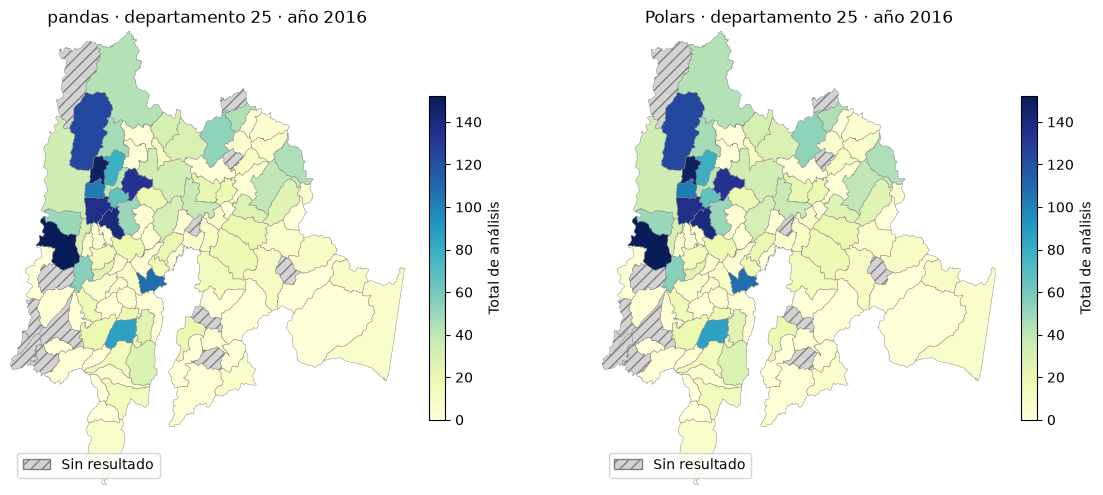

In [16]:
sub_pd = mapa_pd[mapa_pd["codigo_municipio"].str[:2] == dep_sel]
sub_pl = mapa_pl[mapa_pl["codigo_municipio"].str[:2] == dep_sel]
limites = sub_pd.total_bounds
VMAX = float(sub_pd["total"].max())

figura = plt.figure(figsize=(14, 7))
ax_pd = figura.add_subplot(1, 2, 1)
ax_pl = figura.add_subplot(1, 2, 2)
for motor in ["pandas", "Polars"]:
    ax = ax_pd if motor == "pandas" else ax_pl
    sub = sub_pd if motor == "pandas" else sub_pl
    sub.plot(column="total", ax=ax, cmap="YlGnBu", vmin=0, vmax=VMAX, edgecolor="grey", linewidth=0.3, legend=True,
             legend_kwds={"label": "Total de análisis", "shrink": 0.6},
             missing_kwds={"color": "lightgrey", "edgecolor": "grey", "hatch": "///"})
    ax.set_xlim(limites[0], limites[2])
    ax.set_ylim(limites[1], limites[3])
    ax.set_title(f"{motor} · departamento {dep_sel} · año {anio_sel}")
    ax.set_axis_off()
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="lightgrey", ec="grey", hatch="///", label="Sin resultado")], loc="lower left")
figura.savefig(OUT + "/comparacion_mapas.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

_Presenta los controles y explica el alcance del resultado._

Los resultados de pandas y de Polars convertido con .to_pandas() después de medir se unen a los mismos polígonos con merge(..., how="left", validate="one_to_one"), con el código como texto y claves únicas verificadas. Las tablas unidas se comparan numéricamente (claves, conteos y medias) antes de mirar los mapas, y ambos mapas comparten extensión, columna, límites de color, leyenda y marca para ausentes.

Se reportan por separado los polígonos sin resultado y los resultados sin geometría.


## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [17]:
# Desarrollo
# Concilia la segunda ejecución, exporta las mediciones y redacta la recomendación.

# Segunda ejecución en una carpeta nueva
EJECUCION = EJECUCION_2
os.makedirs(EJECUCION, exist_ok=False)
proyeccion_pd.to_csv(EJECUCION + "/proyeccion.csv", sep=",", na_rep="", index=False)
proyeccion_pd.to_parquet(EJECUCION + "/proyeccion.parquet", engine="pyarrow", compression="snappy", index=False)

inventarios_2 = {}
for diseno in DISENOS:
    claves = DISENOS[diseno]
    carpeta = Path(EJECUCION) / diseno
    carpeta.mkdir(parents=True, exist_ok=False)
    filas = []
    for numero, (valores, grupo) in enumerate(proyeccion_pd.groupby(claves, dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        fila = dict(zip(claves, valores))
        fila["archivo"] = str(archivo.relative_to(EJECUCION))
        fila["filas"] = len(grupo)
        fila["bytes"] = archivo.stat().st_size
        filas.append(fila)
    inventarios_2[diseno] = pd.DataFrame(filas).astype({"anio": "Int64"})
    inventarios_2[diseno].to_csv(EJECUCION + f"/inventario_{diseno}.csv", index=False)

# Conciliación de contenido entre ejecuciones (los nombres y hashes pueden diferir)
ref = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
for diseno in DISENOS:
    for EJ in [EJECUCION_1, EJECUCION_2]:
        inv = pd.read_csv(EJ + f"/inventario_{diseno}.csv", dtype=TIPOS_INV, keep_default_na=False, na_values=[""])
        partes = [pd.read_parquet(EJ + "/" + ruta, engine="pyarrow") for ruta in inv["archivo"]]
        leido = pd.concat(partes, ignore_index=True).sort_values("id_fila").reset_index(drop=True)
        pd.testing.assert_frame_equal(leido, ref, check_dtype=False)
        assert leido["id_fila"].is_unique and len(leido) == N
    print(diseno, "| ejecuciones equivalentes | archivos:", len(inventarios[diseno]), len(inventarios_2[diseno]))

por_anio | ejecuciones equivalentes | archivos: 12 12
por_anio_depto | ejecuciones equivalentes | archivos: 373 373


In [18]:
# Evidencia: mediciones, inventario de archivos y controles
medidas = pd.DataFrame(registros, columns=COLS_MED)
iniciales = medidas[medidas["repeticion"] == 0]
medidas = medidas[medidas["repeticion"] > 0]
iniciales.to_csv(OUT + "/mediciones_iniciales.csv", index=False)
medidas.to_csv(OUT + "/mediciones.csv", index=False)

medianas = medidas.groupby(["operacion", "formato", "particionamiento", "motor"], as_index=False)["segundos"].agg(mediana="median", minimo="min", maximo="max")
medianas.to_csv(OUT + "/medianas.csv", index=False)
display(medianas.pivot_table(index=["operacion", "formato", "particionamiento"], columns="motor", values="mediana"))

archivos = pd.DataFrame(
    [("unico", 1, os.path.getsize(RUTA_PQ)),
     ("por_anio", len(inventarios["por_anio"]), int(inventarios["por_anio"]["bytes"].sum())),
     ("por_anio_depto", len(inventarios["por_anio_depto"]), int(inventarios["por_anio_depto"]["bytes"].sum()))],
    columns=["diseno", "archivos", "bytes"],
)
archivos["bytes_por_archivo"] = archivos["bytes"] / archivos["archivos"]
archivos.to_csv(OUT + "/inventario_resumen.csv", index=False)
display(archivos)

controles = pd.DataFrame(
    [("filas_proyeccion", N), ("ids_unicos", bool(ref["id_fila"].is_unique)), ("ejecuciones_equivalentes", True),
     ("resultados_equivalentes", len(resultados)), ("anio_sel", anio_sel), ("departamento_sel", dep_sel)],
    columns=["control", "valor"],
)
controles.to_csv(OUT + "/controles_equivalencia.csv", index=False)

motor                                          pandas    polars
operacion          formato particionamiento                    
consulta_diferida  parquet unico                  NaN  0.070056
consulta_disco     parquet por_anio          0.060813  0.100582
                           por_anio_depto    0.068967  0.106453
                           unico             0.062502  0.118001
consulta_inmediata parquet unico                  NaN  0.091125
escribir           csv     unico             0.950386  0.181494
                   parquet unico             0.173699  0.066038
filtrar_agregar    memoria tabla_en_memoria  0.013607  0.021185
leer               csv     unico             0.154641  0.082746
                   parquet unico             0.047340  0.069381

,diseno,archivos,bytes,bytes_por_archivo
0,unico,1,830508,830508.000000
1,por_anio,12,864848,72070.666667
2,por_anio_depto,373,2250245,6032.828418


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

El contenido de ambas ejecuciones coincide una vez ordenado por id_fila y el total de registros se conserva; los nombres o hashes de archivo no tienen por qué coincidir. Se guardaron mediciones.csv (repeticiones 1-5), mediciones_iniciales.csv, medianas.csv, inventario_resumen.csv y controles_equivalencia.csv.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.